# Klasifikasi Citra Penyakit Kulit MonkeyPox (MSLD v2.0)
**Arsitektur:** MobileNetV3-Small + Pre-processing CLAHE (5-Fold Cross Validation)

In [ ]:
from google.colab import drive
import zipfile, os

drive.mount('/content/drive')

zip_path = '/content/drive/MyDrive/Dataset_Mpox.zip'
extract_path = '/content/DATASET_MPOX'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Ekstrak selesai! Isi folder:", os.listdir(extract_path))

Mounted at /content/drive
Ekstrak selesai! Isi folder: ['Original Images', 'Keywords.jpg', 'datalog.xlsx', 'Augmented Images']


### Cell 1: Import Library & Konfigurasi Dasar

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import MobileNet_V3_Small_Weights

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

CONFIG = {
    "seed": 42,
    "dataset_root": "./DATASET_MPOX",
    "output_dir": "./outputs",
    "checkpoint_dir": "./checkpoints",
    "img_size": 224,
    "batch_size": 32,
    "num_folds": 5,
    "epochs": 10,
    "learning_rate": 3e-4,
    "weight_decay": 1e-2,
    "use_clahe": True,
    "num_workers": 2,
    "device": "cuda" if torch.cuda.is_available() else "cpu"
}

os.makedirs(CONFIG["output_dir"], exist_ok=True)
os.makedirs(CONFIG["checkpoint_dir"], exist_ok=True)

def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(CONFIG["seed"])
print(f"Setup selesai. Device aktif: {CONFIG['device']} | CLAHE: {CONFIG['use_clahe']}")

Setup selesai. Device aktif: cuda | CLAHE: True


### Cell 2: Pre-processing Gambar (CLAHE) & Transformasi

In [ ]:
class ApplyCLAHE:
    def __init__(self, clip_limit=2.0, tile_grid_size=(8, 8)):
        self.clip_limit = clip_limit
        self.tile_grid_size = tile_grid_size

    def __call__(self, img: Image.Image) -> Image.Image:
        img_np = np.array(img)
        lab = cv2.cvtColor(img_np, cv2.COLOR_RGB2LAB)
        l_channel, a_channel, b_channel = cv2.split(lab)

        clahe = cv2.createCLAHE(
            clipLimit=self.clip_limit,
            tileGridSize=self.tile_grid_size
        )
        l_clahe = clahe.apply(l_channel)

        merged_lab = cv2.merge((l_clahe, a_channel, b_channel))
        rgb_clahe = cv2.cvtColor(merged_lab, cv2.COLOR_LAB2RGB)
        return Image.fromarray(rgb_clahe)


def get_transforms(img_size: int, use_clahe: bool = True):
    base_preprocess = [ApplyCLAHE()] if use_clahe else []

    train_transform = transforms.Compose(
        base_preprocess + [
            transforms.Resize((img_size, img_size)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ]
    )

    eval_transform = transforms.Compose(
        base_preprocess + [
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ]
    )
    return train_transform, eval_transform

print("Fungsi Pre-processing CLAHE siap.")

Fungsi Pre-processing CLAHE siap.


### Cell 3: Dataset Loader & Pengecekan Struktur Folder MSLD v2.0

In [ ]:
def find_fold_dirs(root_dir: str, fold_num: int):
    orig_train, aug_train, orig_valid, orig_test = None, None, None, None
    fold_tag = f"fold{fold_num}"

    for dirpath, _, _ in os.walk(root_dir):
        norm_path = dirpath.replace("\\", "/").lower()
        base_name = os.path.basename(dirpath).lower()

        if fold_tag in norm_path:
            is_aug = "aug" in norm_path
            if base_name == "train":
                if is_aug:
                    aug_train = dirpath
                else:
                    orig_train = dirpath
            elif base_name == "valid" and not is_aug:
                orig_valid = dirpath
            elif base_name == "test" and not is_aug:
                orig_test = dirpath

    if not all([orig_train, aug_train, orig_valid, orig_test]):
        raise FileNotFoundError(
            f"Struktur folder {fold_tag} tidak lengkap di '{root_dir}'.\n"
            f"orig_train: {orig_train}, aug_train: {aug_train}, "
            f"orig_valid: {orig_valid}, orig_test: {orig_test}"
        )
    return orig_train, aug_train, orig_valid, orig_test


def load_images_from_dirs(dir_list: list, class_to_idx: dict):
    filepaths, labels = [], []
    valid_ext = (".jpg", ".jpeg", ".png", ".bmp")

    for d in dir_list:
        for class_name, idx in class_to_idx.items():
            class_dir = os.path.join(d, class_name)
            if not os.path.isdir(class_dir):
                raise FileNotFoundError(f"Folder kelas '{class_name}' tidak ditemukan di '{d}'")
            for fname in sorted(os.listdir(class_dir)):
                if fname.lower().endswith(valid_ext):
                    filepaths.append(os.path.join(class_dir, fname))
                    labels.append(idx)

    return np.array(filepaths), np.array(labels)


class SkinLesionDataset(Dataset):
    def __init__(self, filepaths, labels, transform=None):
        self.filepaths = filepaths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):
        img = Image.open(self.filepaths[idx]).convert("RGB")
        label = int(self.labels[idx])
        if self.transform:
            img = self.transform(img)
        return img, label

# Tes pembacaan dataset pada Fold 1 sebelum training dimulai
orig_tr_1, aug_tr_1, orig_val_1, orig_ts_1 = find_fold_dirs(CONFIG["dataset_root"], 1)
TARGET_CLASSES = sorted([
    d for d in os.listdir(orig_tr_1)
    if os.path.isdir(os.path.join(orig_tr_1, d))
])
CLASS_TO_IDX = {cls_name: i for i, cls_name in enumerate(TARGET_CLASSES)}
print(f"Dataset terbaca dengan sukses! Kelas ({len(TARGET_CLASSES)}): {TARGET_CLASSES}")

Dataset terbaca dengan sukses! Kelas (6): ['Chickenpox', 'Cowpox', 'HFMD', 'Healthy', 'Measles', 'Monkeypox']


### Cell 4: Arsitektur Model & Fungsi Training / Evaluasi

In [ ]:
def build_model(num_classes: int, device: str):
    model = models.mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT)
    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(in_features, num_classes)
    )
    return model.to(device)


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    all_preds, all_targets = [], []

    for images, targets in loader:
        images, targets = images.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())

    return running_loss / len(loader.dataset), accuracy_score(all_targets, all_preds)


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_targets, all_preds, all_probs = [], [], []

    for images, targets in loader:
        images, targets = images.to(device), targets.to(device)
        outputs = model(images)
        loss = criterion(outputs, targets)

        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(probs, dim=1)

        running_loss += loss.item() * images.size(0)
        all_targets.extend(targets.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

    y_true = np.array(all_targets)
    y_pred = np.array(all_preds)
    y_prob = np.array(all_probs)

    return {
        "loss": running_loss / len(loader.dataset),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_score": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro"),
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob
    }

print("Arsitektur MobileNetV3-Small & fungsi evaluasi siap.")

Arsitektur MobileNetV3-Small & fungsi evaluasi siap.


### Cell 5: Eksekusi Training & Evaluasi 5-Fold Cross Validation

In [ ]:
train_tf, eval_tf = get_transforms(CONFIG["img_size"], CONFIG["use_clahe"])
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

val_results, test_results, histories = [], [], []
all_test_y_true, all_test_y_pred, all_test_y_prob = [], [], []

for fold in range(1, CONFIG["num_folds"] + 1):
    print(f"\n{'='*50}\nMEMULAI FOLD {fold}/{CONFIG['num_folds']}\n{'='*50}")

    orig_tr, aug_tr, orig_val, orig_ts = find_fold_dirs(CONFIG["dataset_root"], fold)

    X_train, y_train = load_images_from_dirs([orig_tr, aug_tr], CLASS_TO_IDX)
    X_val, y_val = load_images_from_dirs([orig_val], CLASS_TO_IDX)
    X_test, y_test = load_images_from_dirs([orig_ts], CLASS_TO_IDX)

    print(f"Fold {fold} -> Train: {len(X_train)} | Valid: {len(X_val)} | Test: {len(X_test)}")

    train_loader = DataLoader(
        SkinLesionDataset(X_train, y_train, transform=train_tf),
        batch_size=CONFIG["batch_size"], shuffle=True, num_workers=CONFIG["num_workers"]
    )
    val_loader = DataLoader(
        SkinLesionDataset(X_val, y_val, transform=eval_tf),
        batch_size=CONFIG["batch_size"], shuffle=False, num_workers=CONFIG["num_workers"]
    )
    test_loader = DataLoader(
        SkinLesionDataset(X_test, y_test, transform=eval_tf),
        batch_size=CONFIG["batch_size"], shuffle=False, num_workers=CONFIG["num_workers"]
    )

    model = build_model(len(TARGET_CLASSES), CONFIG["device"])
    optimizer = optim.AdamW(
        model.parameters(),
        lr=CONFIG["learning_rate"],
        weight_decay=CONFIG["weight_decay"]
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG["epochs"])

    best_val_f1 = 0.0
    best_ckpt_path = os.path.join(CONFIG["checkpoint_dir"], f"mobilenetv3_fold{fold}.pth")
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(1, CONFIG["epochs"] + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, CONFIG["device"])
        val_metrics = evaluate(model, val_loader, criterion, CONFIG["device"])
        scheduler.step()

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(val_metrics["accuracy"])

        print(
            f"Epoch [{epoch:02d}/{CONFIG['epochs']:02d}] | "
            f"Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} Acc: {val_metrics['accuracy']:.4f} "
            f"F1: {val_metrics['f1_score']:.4f} AUC: {val_metrics['roc_auc']:.4f}"
        )

        if val_metrics["f1_score"] >= best_val_f1:
            best_val_f1 = val_metrics["f1_score"]
            torch.save(model.state_dict(), best_ckpt_path)

    histories.append(history)

    model.load_state_dict(torch.load(best_ckpt_path, map_location=CONFIG["device"]))
    best_val = evaluate(model, val_loader, criterion, CONFIG["device"])
    best_test = evaluate(model, test_loader, criterion, CONFIG["device"])

    val_results.append({
        "Fold": f"Fold {fold}", "Split": "Validation",
        "Accuracy": best_val["accuracy"], "Precision": best_val["precision"],
        "Recall": best_val["recall"], "F1_Score": best_val["f1_score"],
        "ROC_AUC": best_val["roc_auc"]
    })

    test_results.append({
        "Fold": f"Fold {fold}", "Split": "Test",
        "Accuracy": best_test["accuracy"], "Precision": best_test["precision"],
        "Recall": best_test["recall"], "F1_Score": best_test["f1_score"],
        "ROC_AUC": best_test["roc_auc"]
    })

    all_test_y_true.extend(best_test["y_true"])
    all_test_y_pred.extend(best_test["y_pred"])
    all_test_y_prob.extend(best_test["y_prob"])


MEMULAI FOLD 1/5
Fold 1 -> Train: 8055 | Valid: 144 | Test: 74
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 130MB/s]


Epoch [01/10] | Train Loss: 0.7900 Acc: 0.8437 | Val Loss: 0.9888 Acc: 0.7153 F1: 0.6681 AUC: 0.9447
Epoch [02/10] | Train Loss: 0.5334 Acc: 0.9693 | Val Loss: 0.9294 Acc: 0.7847 F1: 0.7568 AUC: 0.9589
Epoch [03/10] | Train Loss: 0.4888 Acc: 0.9873 | Val Loss: 0.9488 Acc: 0.7569 F1: 0.7133 AUC: 0.9333
Epoch [04/10] | Train Loss: 0.4703 Acc: 0.9935 | Val Loss: 0.9522 Acc: 0.7569 F1: 0.7287 AUC: 0.9572
Epoch [05/10] | Train Loss: 0.4602 Acc: 0.9948 | Val Loss: 0.9446 Acc: 0.7708 F1: 0.7368 AUC: 0.9387
Epoch [06/10] | Train Loss: 0.4516 Acc: 0.9974 | Val Loss: 0.8950 Acc: 0.7847 F1: 0.7619 AUC: 0.9611
Epoch [07/10] | Train Loss: 0.4465 Acc: 0.9986 | Val Loss: 0.8918 Acc: 0.7639 F1: 0.7303 AUC: 0.9600
Epoch [08/10] | Train Loss: 0.4424 Acc: 0.9991 | Val Loss: 0.8894 Acc: 0.7708 F1: 0.7321 AUC: 0.9622
Epoch [09/10] | Train Loss: 0.4404 Acc: 0.9991 | Val Loss: 0.9003 Acc: 0.7569 F1: 0.7242 AUC: 0.9605
Epoch [10/10] | Train Loss: 0.4398 Acc: 0.9991 | Val Loss: 0.8926 Acc: 0.7708 F1: 0.7449 AU

### Cell 6: Rekapitulasi Tabel Metrik & Visualisasi Grafik (Untuk GitHub & Laporan)

,Fold,Split,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Fold 1,Validation,0.784722,0.802881,0.741532,0.761868,0.961101
1,Fold 2,Validation,0.871951,0.850494,0.875256,0.860533,0.984811
2,Fold 3,Validation,0.784314,0.769434,0.776592,0.771873,0.896345
3,Fold 4,Validation,0.873333,0.871594,0.813888,0.836528,0.953930
4,Fold 5,Validation,0.818182,0.822503,0.797205,0.800212,0.967134
5,Fold 1,Test,0.837838,0.921131,0.773093,0.814182,0.907756
6,Fold 2,Test,0.792683,0.784788,0.799487,0.789481,0.936467
7,Fold 3,Test,0.828125,0.822150,0.799684,0.808479,0.948217
8,Fold 4,Test,0.765432,0.792807,0.787144,0.784244,0.969058
9,Fold 5,Test,0.904762,0.940241,0.859788,0.880770,0.979549


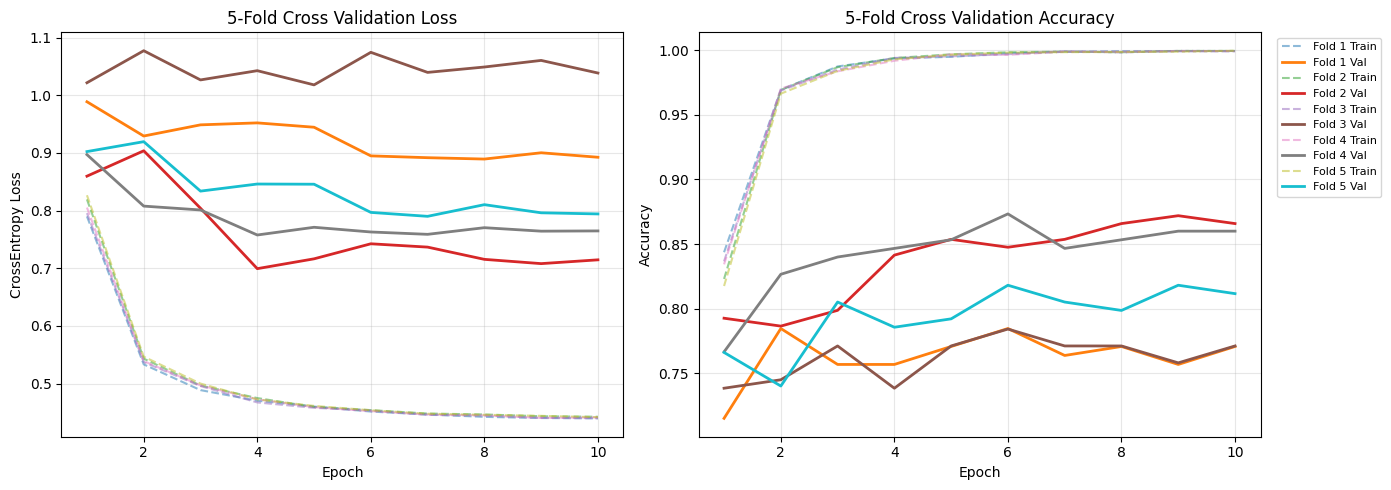

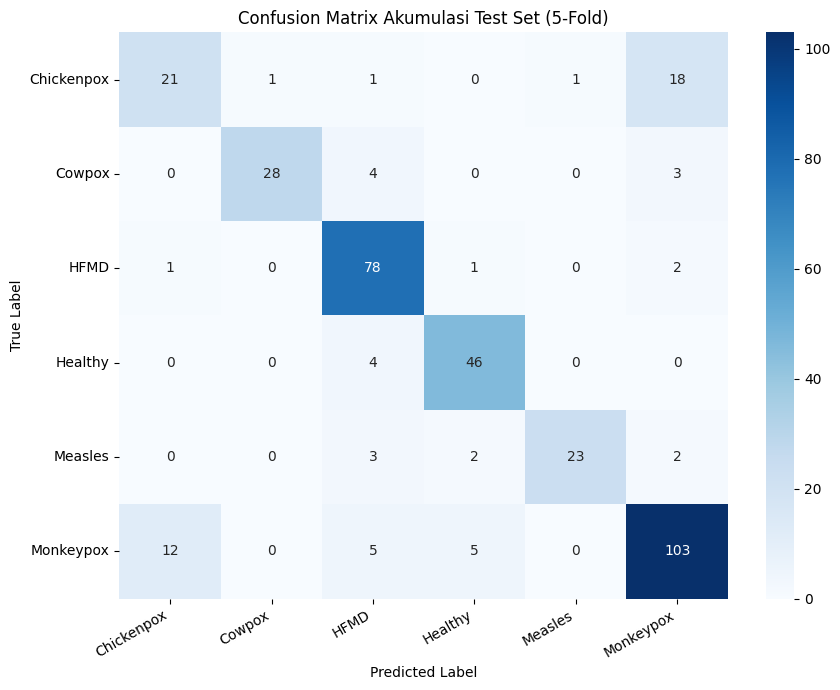

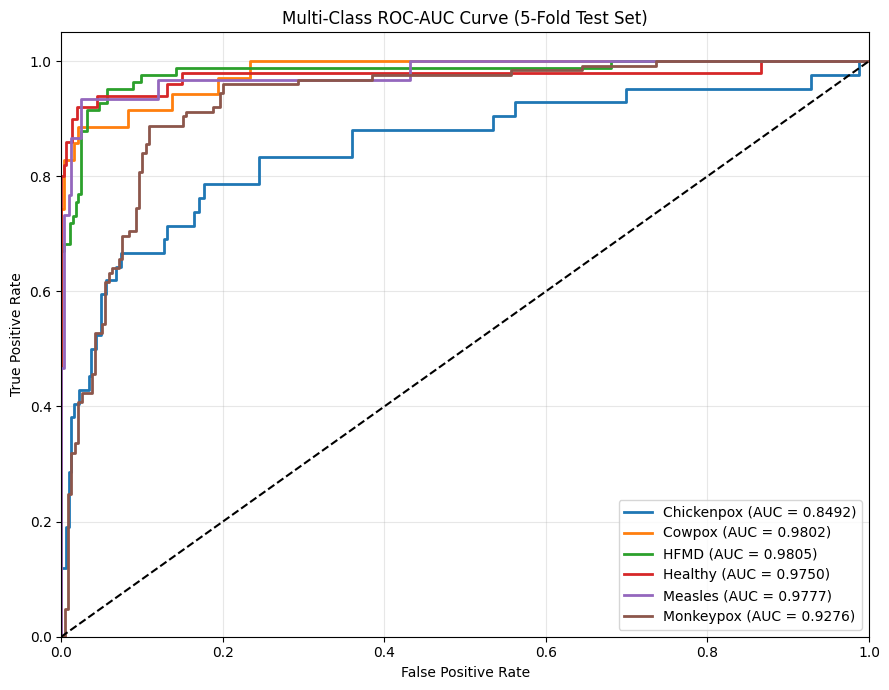

In [ ]:
df_val = pd.DataFrame(val_results)
df_test = pd.DataFrame(test_results)

mean_val = df_val.iloc[:, 2:].mean().to_dict()
mean_test = df_test.iloc[:, 2:].mean().to_dict()

summary_rows = [
    {"Fold": "Mean (5-Fold)", "Split": "Validation", **mean_val},
    {"Fold": "Mean (5-Fold)", "Split": "Test", **mean_test}
]
df_all = pd.concat([df_val, df_test, pd.DataFrame(summary_rows)], ignore_index=True)
df_all.to_csv(os.path.join(CONFIG["output_dir"], "metrics_summary.csv"), index=False)

display(df_all)

# 1. Grafik Training & Validation Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs_range = range(1, CONFIG["epochs"] + 1)
for fold_idx, h in enumerate(histories, 1):
    axes[0].plot(epochs_range, h["train_loss"], linestyle="--", alpha=0.5, label=f"Fold {fold_idx} Train")
    axes[0].plot(epochs_range, h["val_loss"], linewidth=2, label=f"Fold {fold_idx} Val")
    axes[1].plot(epochs_range, h["train_acc"], linestyle="--", alpha=0.5, label=f"Fold {fold_idx} Train")
    axes[1].plot(epochs_range, h["val_acc"], linewidth=2, label=f"Fold {fold_idx} Val")

axes[0].set_title("5-Fold Cross Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("CrossEntropy Loss")
axes[0].grid(True, alpha=0.3)

axes[1].set_title("5-Fold Cross Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "training_curves_5fold.png"), dpi=300, bbox_inches="tight")
plt.show()

# 2. Confusion Matrix
cm = confusion_matrix(np.array(all_test_y_true), np.array(all_test_y_pred))
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=TARGET_CLASSES, yticklabels=TARGET_CLASSES)
plt.title("Confusion Matrix Akumulasi Test Set (5-Fold)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "confusion_matrix_test.png"), dpi=300)
plt.show()

# 3. Multi-Class ROC-AUC Curve
y_true_arr = np.array(all_test_y_true)
y_prob_arr = np.array(all_test_y_prob)
y_true_bin = label_binarize(y_true_arr, classes=list(range(len(TARGET_CLASSES))))

plt.figure(figsize=(9, 7))
for i in range(len(TARGET_CLASSES)):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob_arr[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"{TARGET_CLASSES[i]} (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], "k--", lw=1.5)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi-Class ROC-AUC Curve (5-Fold Test Set)")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "roc_auc_multiclass.png"), dpi=300)
plt.show()